# Practical 6 — Learning a Component Defect Rate
### A short workshop on Bernoulli observations, a Beta prior, and probabilistic learning


## Learning outcomes

By the end of the workshop, you should be able to:

1. translate a binary real-world observation into a Bernoulli model;
2. distinguish observations from an unknown model parameter;
3. construct a likelihood and a maximum-likelihood estimate (MLE);
4. update a Beta prior to obtain a posterior distribution;
5. compare MLE, MAP, and full Bayesian prediction; and
6. use posterior uncertainty in a simple decision.

> Work through the questions **before** running the code. The code then checks and visualises your reasoning.

# Part 1 — The real-world problem

A manufacturer has installed a new production line for electronic components. Each inspected component is recorded as either:

- `1`: defective;
- `0`: acceptable.

The first pilot batch gives the following inspection results:

```text
0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
0, 0, 1, 0, 0, 1, 0, 0, 0, 0
```

The true long-run **defect probability** of the new line is unknown. Denote it by

$$
\theta=P(\text{a component is defective}).
$$

Experience with comparable production lines suggests that defect rates are usually low. The engineers encode this information using

$$
\theta\sim \operatorname{Beta}(2,18),
$$

whose prior mean is $2/(2+18)=0.10$.

Management wants to answer four practical questions:

1. What defect probability is suggested by the pilot data alone?
2. How should the historical knowledge and pilot data be combined?
3. What is the probability that the **next** component is defective?
4. Is there strong evidence that the true defect rate exceeds the concern level $\theta_c=0.15$?

For this workshop, management escalates the process only when

$$
P(\theta>0.15\mid D)>0.80.
$$

This rule is used only to demonstrate decision-making under uncertainty.

# Part 2 — Problem formulation and probabilistic model

## 2.1 Bernoulli observations

Let $X_i$ denote the inspection result for component $i$:

$$
X_i=
\begin{cases}
1, & \text{component }i\text{ is defective},\\
0, & \text{component }i\text{ is acceptable}.
\end{cases}
$$

Conditioned on the unknown defect probability $\theta$, one observation is modelled as

$$
X_i\mid\theta\sim\operatorname{Bernoulli}(\theta),
$$

with

$$
P(X_i=x_i\mid\theta)
=\theta^{x_i}(1-\theta)^{1-x_i},
\qquad x_i\in\{0,1\}.
$$

The Bernoulli distribution is a distribution over an **observed binary outcome**. It is not a distribution over $\theta$.

## 2.2 Assumptions about the observations

We assume that, conditioned on one fixed value of $\theta$, the observations are independent and identically distributed:

$$
X_1,\ldots,X_N\mid\theta
\overset{\mathrm{i.i.d.}}{\sim}
\operatorname{Bernoulli}(\theta).
$$

This assumes that the defect probability remains approximately constant over the pilot batch and that one inspection result does not directly change another.

If $d=\sum_i x_i$ components are defective and $g=N-d$ are acceptable, the likelihood is

$$
P(D\mid\theta)
=\prod_{i=1}^{N}P(x_i\mid\theta)
=\theta^d(1-\theta)^g.
$$

## 2.3 Beta prior over the unknown probability

In Bayesian learning, uncertainty about $\theta$ is represented by a Beta distribution:

$$
\theta\sim\operatorname{Beta}(\alpha_0,\beta_0),
$$

where

$$
p(\theta)
=\frac{1}{B(\alpha_0,\beta_0)}
\theta^{\alpha_0-1}(1-\theta)^{\beta_0-1},
\qquad 0<\theta<1.
$$

Its mean is

$$
E[\theta]=\frac{\alpha_0}{\alpha_0+\beta_0}.
$$

The two shape parameters update like prior pseudo-counts: observed defects are added to $\alpha_0$, while acceptable components are added to $\beta_0$.

## 2.4 The complete model and the learning direction

The complete generative model is

$$
\boxed{
\theta\sim\operatorname{Beta}(\alpha_0,\beta_0),
\qquad
X_i\mid\theta\sim\operatorname{Bernoulli}(\theta)
}
$$

and its joint distribution factorises as

$$
p(\theta,x_{1:N})
=p(\theta)\prod_{i=1}^{N}p(x_i\mid\theta).
$$

The model generates observations in the direction

$$
\theta\longrightarrow X_1,\ldots,X_N.
$$

Learning solves the reverse inference problem: after observing $D$, compute

$$
p(\theta\mid D)
\propto P(D\mid\theta)p(\theta).
$$

Because a Beta prior is conjugate to a Bernoulli likelihood, the posterior is also Beta. The questions below ask you to work out its parameters and compare three learning outputs:

- **MLE:** one estimate based only on the likelihood;
- **MAP:** one estimate at the posterior mode;
- **full Bayesian learning:** the complete posterior, used for uncertainty and prediction.

# Part 3 — Questions to answer before coding

Use the pilot observations and the model above. Show the main steps, not only the final numbers.

## Question 1 — Identify the model quantities


1. What are the observed random variables?
2. What is the unknown parameter?
3. What do the values `1` and `0` mean?
4. Write the factorisation of the joint model $p(\theta,x_{1:N})$.
5. State one real-world situation in which the i.i.d. assumption may fail.

### Answer — Question 1: Model Quantities

1. **Observed Random Variables:**
   - $X_1, X_2, \ldots, X_N$ representing the individual inspection outcomes of the $N = 20$ components in the pilot batch ($X_i \in \{0, 1\}$ for $i = 1, \ldots, 20$).

2. **Unknown Parameter:**
   - $\theta \in (0, 1)$, representing the long-run defect probability of the new component production line.

3. **Interpretation of Binary Values:**
   - `1`: Component is **defective**.
   - `0`: Component is **acceptable** (non-defective).

4. **Factorisation of Joint Model:**
   - The joint distribution factorises as:
     $$p(\theta, x_{1:N}) = p(\theta) \prod_{i=1}^{N} P(x_i \mid \theta)$$
     where $p(\theta) = \operatorname{Beta}(\theta; \alpha_0, \beta_0)$ is the prior distribution over $\theta$, and $P(x_i \mid \theta) = \theta^{x_i}(1-\theta)^{1-x_i}$ is the Bernoulli likelihood for observation $i$.

5. **Failure of the i.i.d. Assumption in Practice:**
   - The identical distribution assumption can fail due to **cutting tool wear**, **machine thermal drift**, or **raw material batch fluctuations**. As production runs, tool wear gradually increases the defect probability $\theta_i$ over time (non-identical). The independence assumption can fail if a machine failure causes consecutive defective components (correlated observations).


## Question 2 — Likelihood and maximum likelihood


1. Count the number of observations $N$, defects $d$, and acceptable components $g$.
2. Write the likelihood $P(D\mid\theta)$, ignoring constants that do not depend on $\theta$.
3. Compute the maximum-likelihood estimate
   $$
   \hat\theta_{\mathrm{ML}}=\arg\max_\theta P(D\mid\theta).
   $$
4. Explain in one sentence what this estimate means.

### Answer — Question 2: Likelihood and Maximum Likelihood

1. **Summary Counts from Pilot Data:**
   - Total components inspected: $N = 20$
   - Defective components: $d = 4$
   - Acceptable components: $g = N - d = 16$

2. **Likelihood Function $P(D \mid \theta)$:**
   - Ignoring multiplicative constants independent of $\theta$:
     $$P(D \mid \theta) = \prod_{i=1}^{N} \theta^{x_i}(1-\theta)^{1-x_i} = \theta^d (1-\theta)^g = \theta^4 (1-\theta)^{16}$$

3. **Derivation of Maximum-Likelihood Estimate (MLE):**
   - Taking the natural log of the likelihood:
     $$\ln P(D \mid \theta) = d \ln \theta + g \ln (1-\theta)$$
   - Setting the derivative with respect to $\theta$ to zero:
     $$\frac{d}{d\theta} \ln P(D \mid \theta) = \frac{d}{\theta} - \frac{g}{1-\theta} = 0 \implies d(1-\theta) = g\theta \implies \theta(d+g) = d$$
   - Thus, the MLE estimator is:
     $$\hat\theta_{\mathrm{ML}} = \frac{d}{N} = \frac{4}{20} = 0.20$$

4. **One-Sentence Interpretation:**
   - The Maximum Likelihood Estimate ($\hat\theta_{\mathrm{ML}} = 0.20$) represents the single defect probability that maximizes the chance of observing the pilot sample of 4 defects out of 20 components, relying exclusively on empirical data without incorporating prior domain knowledge.


## Question 3 — Prior-to-posterior update


The prior is $\operatorname{Beta}(2,18)$.

1. What is its prior mean?
2. Multiply the likelihood by the prior and identify the posterior distribution.
3. State the posterior parameters $\alpha_N$ and $\beta_N$.
4. Compute the posterior mean and explain why it lies between the prior mean and the MLE.

### Answer — Question 3: Prior-to-Posterior Update

1. **Prior Mean:**
   - For a $\operatorname{Beta}(\alpha_0=2, \beta_0=18)$ prior:
     $$\mathbb{E}[\theta] = \frac{\alpha_0}{\alpha_0 + \beta_0} = \frac{2}{2 + 18} = \frac{2}{20} = 0.10$$

2. **Posterior Distribution via Bayes' Rule:**
   - Multiplying the likelihood by the prior:
     $$p(\theta \mid D) \propto P(D \mid \theta) p(\theta) \propto \left[\theta^d (1-\theta)^g\right] \cdot \left[\theta^{\alpha_0 - 1}(1-\theta)^{\beta_0 - 1}\right] = \theta^{(\alpha_0 + d) - 1} (1-\theta)^{(\beta_0 + g) - 1}$$
   - Because this kernel matches a Beta density, the posterior distribution is:
     $$\theta \mid D \sim \operatorname{Beta}(\alpha_N, \beta_N)$$

3. **Posterior Parameters:**
   - $\alpha_N = \alpha_0 + d = 2 + 4 = 6$
   - $\beta_N = \beta_0 + g = 18 + 16 = 34$
   - Posterior distribution: $\operatorname{Beta}(6, 34)$

4. **Posterior Mean and Weighting Analysis:**
   - Posterior mean:
     $$\mathbb{E}[\theta \mid D] = \frac{\alpha_N}{\alpha_N + \beta_N} = \frac{6}{6 + 34} = \frac{6}{40} = 0.1500$$
   - **Why it lies between the prior mean ($0.10$) and MLE ($0.20$):**
     The posterior mean can be expressed as a convex weighted combination of prior mean and sample MLE:
     $$\mathbb{E}[\theta \mid D] = \frac{\alpha_0 + \beta_0}{\alpha_0 + \beta_0 + N} \left(\frac{\alpha_0}{\alpha_0 + \beta_0}\right) + \frac{N}{\alpha_0 + \beta_0 + N} \left(\frac{d}{N}\right) = \frac{20}{40}(0.10) + \frac{20}{40}(0.20) = 0.1500$$
     Since prior pseudo-counts ($\alpha_0 + \beta_0 = 20$) and sample size ($N = 20$) carry equal weight ($50\%$ each), the posterior mean sits exactly halfway between the prior mean ($0.10$) and sample MLE ($0.20$).


## Question 4 — MLE, MAP, and Bayesian prediction


1. Compute the MAP estimate. For a $\operatorname{Beta}(a,b)$ posterior with $a>1$ and $b>1$,
   $$
   \hat\theta_{\mathrm{MAP}}=\frac{a-1}{a+b-2}.
   $$
2. Compute the Bayesian probability that the next component is defective:
   $$
   P(X_{\mathrm{new}}=1\mid D)
   =\int \theta\,p(\theta\mid D)\,d\theta.
   $$
3. Briefly distinguish MLE, MAP, and full Bayesian prediction.

### Answer — Question 4: MLE, MAP, and Bayesian Prediction

1. **MAP Estimate ($\hat\theta_{\mathrm{MAP}}$):**
   - For a $\operatorname{Beta}(a=6, b=34)$ posterior distribution:
     $$\hat\theta_{\mathrm{MAP}} = \frac{a - 1}{a + b - 2} = \frac{6 - 1}{6 + 34 - 2} = \frac{5}{38} \approx 0.1316$$

2. **Bayesian Probability that the Next Component is Defective:**
   - Marginalizing over parameter uncertainty:
     $$P(X_{\mathrm{new}} = 1 \mid D) = \int_0^1 \theta \, p(\theta \mid D) \, d\theta = \mathbb{E}[\theta \mid D] = \frac{\alpha_N}{\alpha_N + \beta_N} = \frac{6}{40} = 0.1500$$

3. **Distinction between MLE, MAP, and Full Bayesian Prediction:**
   - **MLE ($\hat\theta_{\mathrm{ML}} = 0.20$):** A point estimate optimizing likelihood only. Ignores prior domain knowledge and suffers from high variance with small datasets.
   - **MAP ($\hat\theta_{\mathrm{MAP}} \approx 0.1316$):** A point estimate located at the posterior *mode* (peak density), balancing prior knowledge and data.
   - **Full Bayesian Prediction ($P(X_{\mathrm{new}}=1 \mid D) = 0.1500$):** Integrates over *all possible values of $\theta$* weighted by their posterior probabilities, fully preserving parameter uncertainty rather than collapsing the distribution to a single point.


## Question 5 — Uncertainty and a process decision


1. Which posterior quantity should be computed to assess whether the true defect rate exceeds 0.15?
2. Why is the statement $\hat\theta_{\mathrm{ML}}=0.20>0.15$ not by itself a measure of strong evidence?
3. Predict what will happen to the posterior when substantially more data are collected.
4. Predict what will happen when a much stronger prior with the same mean of 0.10 is used.

### Answer — Question 5: Uncertainty and Process Decision

1. **Required Posterior Quantity:**
   - Compute the posterior tail probability that the defect rate exceeds concern level $\theta_c = 0.15$:
     $$P(\theta > 0.15 \mid D) = \int_{0.15}^{1} p(\theta \mid D) \, d\theta = 1 - F_{\operatorname{Beta}(6, 34)}(0.15)$$

2. **Why $\hat\theta_{\mathrm{ML}} = 0.20 > 0.15$ is Not Strong Evidence:**
   - With $N = 20$, sample noise is significant (standard error $\approx \sqrt{0.2 \times 0.8 / 20} \approx 0.089$). Observing 4 defects out of 20 can easily happen by random chance even when the true rate $\theta \le 0.15$. MLE ignores sample size uncertainty and historical prior expectations.

3. **Asymptotic Behavior with Substantially More Data ($N \to \infty$):**
   - As $N \to \infty$, the posterior distribution contracts to a sharp peak around the true parameter $\theta_*$, posterior variance approaches zero, and the influence of the prior vanishes (asymptotic consistency).

4. **Effect of a Stronger Prior (e.g., $\operatorname{Beta}(20, 180)$ with mean $0.10$):**
   - A stronger prior (carrying 200 pseudo-counts) heavily anchors the posterior near $0.10$, reducing posterior variance and requiring a significantly larger sample of defects to shift the posterior mean toward $0.15$.


# Part 4 — Python workshop

The code now implements the analysis in the same order as the questions:

$$
\text{data}
\rightarrow
\text{likelihood and MLE}
\rightarrow
\text{prior}
\rightarrow
\text{posterior and MAP}
\rightarrow
\text{prediction and decision}.
$$

## Setup

The observations and prior are supplied. Run this cell first.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

inspection_data = np.array([
    0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
    0, 0, 1, 0, 0, 1, 0, 0, 0, 0
], dtype=int)

alpha0 = 2
beta0 = 18
concern_threshold = 0.15
decision_probability = 0.80

## Code task 1 — Summarise the observations and compute the MLE

Calculate $N$, $d$, $g$, and $\hat	heta_{\mathrm{ML}}$.

In [2]:
# Calculation of N, d, g, and theta_mle
N = len(inspection_data)
d = int(np.sum(inspection_data))
g = N - d
theta_mle = d / N

print(f"Number inspected, N       = {N}")
print(f"Defective components, d   = {d}")
print(f"Acceptable components, g  = {g}")
print(f"MLE of defect probability = {theta_mle:.4f}")

Number inspected, N       = 20
Defective components, d   = 4
Acceptable components, g  = 16
MLE of defect probability = 0.2000


## Code task 2 — Construct the prior and likelihood

Evaluate both functions over a grid of possible values of $	heta$. The likelihood is rescaled to integrate to one only so its shape can be compared with the prior.

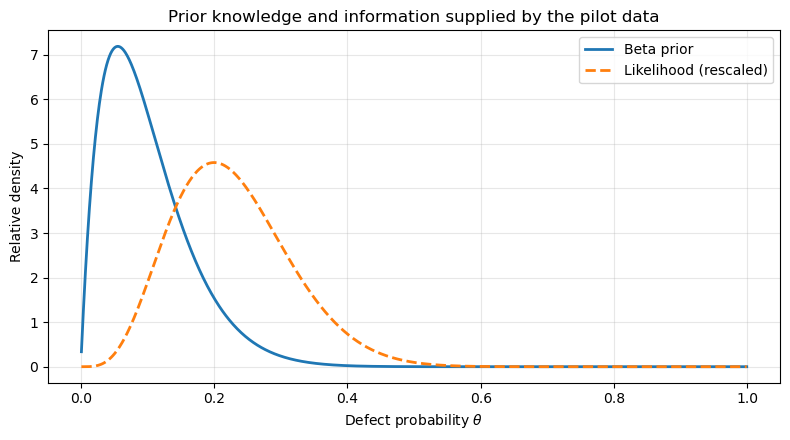

In [3]:
theta_grid = np.linspace(0.001, 0.999, 1000)

# Evaluate the Beta(alpha0, beta0) prior density.
prior_pdf = beta.pdf(theta_grid, alpha0, beta0)

# Evaluate theta^d (1-theta)^g over theta_grid.
likelihood = (theta_grid**d) * ((1 - theta_grid)**g)

# Rescale the likelihood using np.trapezoid so area under curve is 1.
likelihood_rescaled = likelihood / np.trapezoid(likelihood, theta_grid)

# Plot the two curves
plt.figure(figsize=(8, 4.5))
plt.plot(theta_grid, prior_pdf, label="Beta prior", linewidth=2)
plt.plot(theta_grid, likelihood_rescaled, label="Likelihood (rescaled)", linestyle="--", linewidth=2)
plt.xlabel(r"Defect probability $\theta$")
plt.ylabel("Relative density")
plt.title("Prior knowledge and information supplied by the pilot data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Code task 3 — Update the posterior and compare point estimates

Use conjugacy to calculate the posterior parameters, posterior density, MAP estimate, and posterior predictive probability.

In [4]:
# Complete conjugate update and point estimates
alpha_post = alpha0 + d
beta_post = beta0 + g
posterior_pdf = beta.pdf(theta_grid, alpha_post, beta_post)

theta_map = (alpha_post - 1) / (alpha_post + beta_post - 2)
theta_posterior_mean = alpha_post / (alpha_post + beta_post)
p_next_defective = theta_posterior_mean

print(f"Posterior distribution       = Beta({alpha_post}, {beta_post})")
print(f"MLE                          = {theta_mle:.4f}")
print(f"MAP                          = {theta_map:.4f}")
print(f"Posterior mean               = {theta_posterior_mean:.4f}")
print(f"P(next component defective)  = {p_next_defective:.4f}")

Posterior distribution       = Beta(6, 34)
MLE                          = 0.2000
MAP                          = 0.1316
Posterior mean               = 0.1500
P(next component defective)  = 0.1500


## Code task 4 — Verify Bayes' rule numerically and visualise learning

Multiply the prior and likelihood on the grid, normalise the result, and compare it with the analytic Beta posterior.

Maximum grid error: 7.002e-11


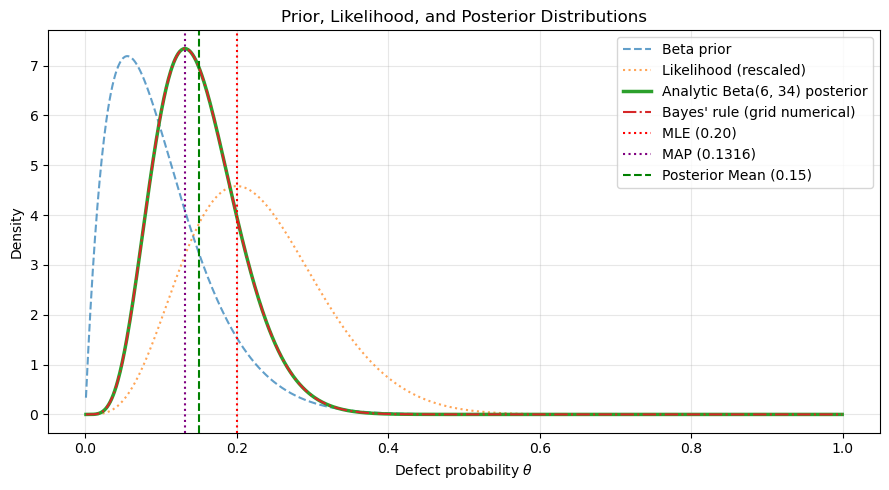

In [5]:
# Multiply prior density by likelihood
posterior_from_bayes = prior_pdf * likelihood

# Normalise so the area under the curve is one
posterior_from_bayes = posterior_from_bayes / np.trapezoid(posterior_from_bayes, theta_grid)

# Compare numerical curve with analytic posterior_pdf
max_error = np.max(np.abs(posterior_from_bayes - posterior_pdf))
print(f"Maximum grid error: {max_error:.3e}")

# Plot prior_pdf, likelihood_rescaled, and posterior_pdf
plt.figure(figsize=(9, 5))
plt.plot(theta_grid, prior_pdf, label="Beta prior", linestyle="--", alpha=0.7)
plt.plot(theta_grid, likelihood_rescaled, label="Likelihood (rescaled)", linestyle=":", alpha=0.7)
plt.plot(theta_grid, posterior_pdf, label=f"Analytic Beta({alpha_post}, {beta_post}) posterior", linewidth=2.5)
plt.plot(theta_grid, posterior_from_bayes, label="Bayes' rule (grid numerical)", linestyle="-.", linewidth=1.5)
plt.axvline(theta_mle, color="red", linestyle=":", label=f"MLE ({theta_mle:.2f})")
plt.axvline(theta_map, color="purple", linestyle=":", label=f"MAP ({theta_map:.4f})")
plt.axvline(theta_posterior_mean, color="green", linestyle="--", label=f"Posterior Mean ({theta_posterior_mean:.2f})")
plt.xlabel(r"Defect probability $\theta$")
plt.ylabel("Density")
plt.title("Prior, Likelihood, and Posterior Distributions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Code task 5 — Quantify uncertainty and apply the decision rule

Compute a 95% credible interval and $P(	heta>0.15\mid D)$. Then apply the stated 0.80 escalation rule.

In [6]:
# Compute central 95% credible interval using beta.ppf
credible_interval = beta.ppf([0.025, 0.975], alpha_post, beta_post)

# Compute P(theta > concern_threshold | data) using beta.cdf
p_above_threshold = 1.0 - beta.cdf(concern_threshold, alpha_post, beta_post)

print(f"95% credible interval for theta = [{credible_interval[0]:.4f}, {credible_interval[1]:.4f}]")
print(f"Posterior probability above threshold = {p_above_threshold:.4f} ({p_above_threshold:.2%})")

# Implement decision rule using decision_probability = 0.80
if p_above_threshold > decision_probability:
    print(f"DECISION: ESCALATE process. (P(theta > {concern_threshold:.2f}) = {p_above_threshold:.2%} > {decision_probability:.0%})")
else:
    print(f"DECISION: DO NOT ESCALATE process. (P(theta > {concern_threshold:.2f}) = {p_above_threshold:.2%} <= {decision_probability:.0%})")

95% credible interval for theta = [0.0586, 0.2743]
Posterior probability above threshold = 0.4586 (45.86%)
DECISION: DO NOT ESCALATE process. (P(theta > 0.15) = 45.86% <= 80%)


## Code task 6 — Observe sequential learning

Recompute MLE, MAP, and Bayesian prediction after each new inspection. This shows why very small samples can give unstable estimates and why the prior matters most near the beginning.

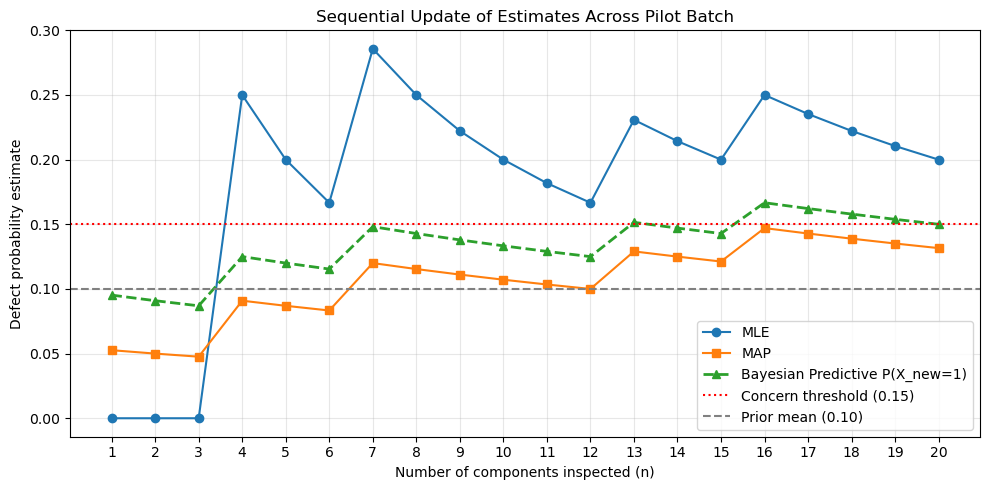

In [7]:
number_seen = np.arange(1, N + 1)
cumulative_defects = np.cumsum(inspection_data)
cumulative_acceptable = number_seen - cumulative_defects

mle_sequence = cumulative_defects / number_seen

alpha_seq = alpha0 + cumulative_defects
beta_seq = beta0 + cumulative_acceptable
map_sequence = (alpha_seq - 1) / (alpha_seq + beta_seq - 2)
predictive_sequence = alpha_seq / (alpha_seq + beta_seq)

plt.figure(figsize=(10, 5))
plt.plot(number_seen, mle_sequence, 'o-', label="MLE", linewidth=1.5)
plt.plot(number_seen, map_sequence, 's-', label="MAP", linewidth=1.5)
plt.plot(number_seen, predictive_sequence, '^--', label="Bayesian Predictive P(X_new=1)", linewidth=2)
plt.axhline(concern_threshold, color='red', linestyle=':', label=f"Concern threshold ({concern_threshold})")
plt.axhline(alpha0 / (alpha0 + beta0), color='gray', linestyle='--', label=f"Prior mean ({alpha0 / (alpha0 + beta0):.2f})")
plt.xlabel("Number of components inspected (n)")
plt.ylabel("Defect probability estimate")
plt.title("Sequential Update of Estimates Across Pilot Batch")
plt.xticks(number_seen)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Part 5 — Discussion and Summary

## Executive Summary & Management Answers

1. **What defect probability is suggested by the pilot data alone?**
   - **$\hat\theta_{\mathrm{ML}} = 0.20$ ($20.00\%$)**.
   - Relying exclusively on the $N=20$ pilot inspections ($d=4$ defects), the raw sample defect rate is $20\%$.

2. **How should historical knowledge and pilot data be combined?**
   - Combine the historical prior $\operatorname{Beta}(\alpha_0=2, \beta_0=18)$ (prior mean $10\%$, equivalent to 20 pseudo-observations) with the pilot observations ($d=4, g=16$) via Bayes' rule.
   - This produces the conjugate posterior $\operatorname{Beta}(\alpha_N=6, \beta_N=34)$ with posterior mean $\mathbb{E}[\theta \mid D] = \frac{6}{40} = 0.1500$ ($15.00\%$).

3. **What is the probability that the next component is defective?**
   - **$P(X_{\mathrm{new}}=1 \mid D) = 0.1500$ ($15.00\%$)**.
   - By integrating over parameter uncertainty (marginalizing out $\theta$), full Bayesian prediction matches the posterior mean.

4. **Is there strong evidence that the true defect rate exceeds concern level $\theta_c = 0.15$?**
   - The posterior probability $P(\theta > 0.15 \mid D)$ is **$45.86\%$**.
   - **Escalation Decision:** Management's rule dictates escalation only when $P(\theta > 0.15 \mid D) > 0.80$. Since $45.86\% \le 80.00\%$, management should **NOT ESCALATE** the process.

---

## Comparison of Learning Outputs

| Estimator / Quantity | Value | Description / Interpretation |
| :--- | :--- | :--- |
| **Prior Mean** | $0.1000$ ($10.0\%$) | Engineering domain expectation before pilot data. |
| **MLE ($\hat\theta_{\mathrm{ML}}$)** | $0.2000$ ($20.0\%$) | Maximizes data likelihood; volatile for small sample sizes. |
| **MAP ($\hat\theta_{\mathrm{MAP}}$)** | $0.1316$ ($13.2\%$) | Mode of posterior; most likely single parameter value given prior + data. |
| **Posterior Mean** | $0.1500$ ($15.0\%$) | Expected defect rate under posterior; equal weighting of prior and sample. |
| **Bayesian Predictive** | $0.1500$ ($15.0\%$) | Probability next item is defective; incorporates full parameter uncertainty. |
| **$95\%$ Credible Interval** | $[0.0586, 0.2743]$ | Range containing true $\theta$ with $95\%$ posterior probability. |
| **$P(\theta > 0.15 \mid D)$** | $0.4586$ ($45.9\%$) | Tail probability above concern threshold (below $80\%$ escalation threshold). |

---

## Key Engineering Takeaways

- **Avoid Overreacting to Small Pilot Batches:** The MLE estimate of $20\%$ is inflated by small-sample random variation. Bayesian update prevents premature alarms by balancing sample data against prior engineering experience.
- **Uncertainty-Aware Decision Making:** Rather than escalating based on a point estimate exceedance ($\hat\theta_{\mathrm{ML}} = 0.20 > 0.15$), computing $P(\theta > 0.15 \mid D) = 45.86\%$ reveals that evidence is inconclusive. The correct operational decision is to collect a larger batch before committing resources to an overhaul.
